In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [2]:
particiones = ['1k', '10k', '100k', '1M', '2M']
procesos = ['P0', 'P1', 'P2', 'P3', 'P4']

In [3]:
calc_times = {
    '1k': [0.262838, 0.263456, 0.263461, 0.264934, 0.264549],
    '10k': [0.212344, 0.212056, 0.212944, 0.213431, 0.213857],
    '100k': [0.203291, 0.206097, 0.209638, 0.212061, 0.214377],
    '1M': [0.157448, 0.190848, 0.213622, 0.232674, 0.249355],
    '2M': [0.110967, 0.179176, 0.220969, 0.253539, 0.280526]
}

sync_times = {
    '1k': [0.0020992, 7.46e-06, 0.00148147, 8.51e-06, 6.5e-06],
    '10k': [0.00151555, 3.2e-07, 0.000488275, 1.1e-06, 2.36e-06],
    '100k': [0.0110847, 1.73e-06, 0.00242926, 2.07e-06, 5.6e-07],
    '1M': [0.0919125, 1.8e-07, 0.0190646, 9.93e-06, 5.91e-06],
    '2M': [0.169569, 3.79e-06, 0.0325806, 6.06e-06, 7e-06]
}

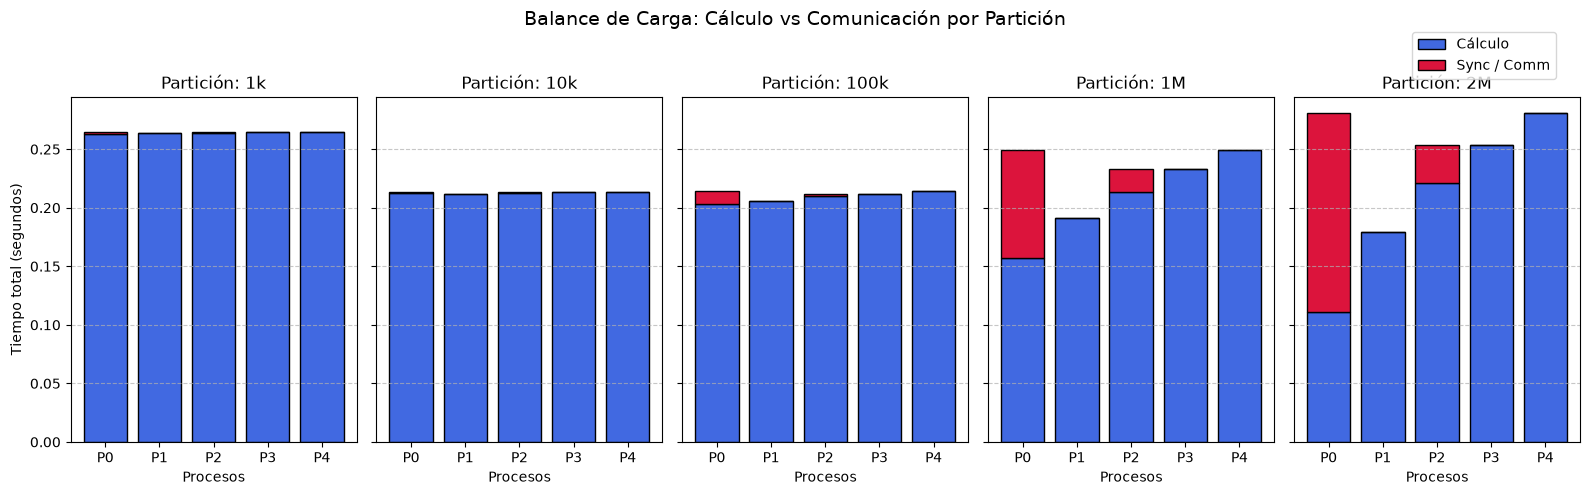

In [4]:

fig, axes = plt.subplots(1, 5, figsize=(16, 5), sharey=True)
fig.suptitle('Balance de Carga: Cálculo vs Comunicación por Partición', fontsize=14)

for i, (part, ax) in enumerate(zip(particiones, axes)):
    calc = np.array(calc_times[part])
    sync = np.array(sync_times[part])

    ax.bar(procesos, calc, label='Cálculo', color='royalblue', edgecolor='black')
    ax.bar(procesos, sync, bottom=calc, label='Sync / Comm', color='crimson', edgecolor='black')

    ax.set_title(f'Partición: {part}')
    ax.set_xlabel('Procesos')
    if i == 0:
        ax.set_ylabel('Tiempo total (segundos)')
    ax.grid(axis='y', linestyle='--', alpha=0.7)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(0.98, 0.95))

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()